# TSLA Random Walk with Drift — frozen historical benchmark and prospective forecasts

This notebook keeps the November 19 frozen benchmark separate from live forecasts. Select hyperparameters using training and validation only; do not tune using test results.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / "pyproject.toml").is_file()
                     and (p / "shared_code").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within timeseriesproj")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared_code.visualization.exporting import (
    save_figure,
    save_table,
)

FIGURES_DIR = PROJECT_ROOT / "stock_pred" / "figures" / "random_walk_drift"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

from shared_code.models.random_walk_drift import RandomWalkDrift
from shared_code.evaluation.diagnostics import training_diagnostic_table, ljung_box_test
from shared_code.evaluation.metrics import interval_summary, compare_point_forecasts
from shared_code.visualization.plotting import (
    plot_price_return_exploration, plot_training_acf_pacf,
    plot_backtest_comparison, plot_backtest_errors,
    plot_validation_error_diagnostics, plot_test_intervals_and_errors,
    plot_predictive_cdf, plot_predictive_distribution,
)
from stock_pred.src.full_stock_pred_pipeline import run_forecasting_pipeline

MODEL_CLASS = RandomWalkDrift
MODEL_KWARGS = {}
from shared_code.backtest.splits import fixed_date_split
from shared_code.evaluation.predictive_distribution import EmpiricalPredictiveDistribution
from stock_pred.src.split_config import (
    TRAIN_END_DATE, VALIDATION_END_DATE, TEST_END_DATE,
    HORIZON, WINDOW_SIZE, INTERVAL_LEVEL,
)
CSV_PATH = PROJECT_ROOT / "stock_pred" / "data" / "tsla_historical_data.csv"
SPLITS_DIR = PROJECT_ROOT / "stock_pred" / "data" / "fixed_splits"
RESULTS_DIR = PROJECT_ROOT / "stock_pred" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# Dates come from stock_pred/src/split_config.py (shared by all four notebooks).
print("Train cutoff:", TRAIN_END_DATE.date())
print("Validation cutoff:", VALIDATION_END_DATE.date())
print("Frozen test cutoff:", TEST_END_DATE.date())


Train cutoff: 2024-11-07
Validation cutoff: 2025-11-10
Frozen test cutoff: 2026-11-19


In [3]:
from stock_pred.src.data.import_data import update_market_data

updated_df, updated_at = update_market_data(
    ticker="TSLA",
    start_date="2021-11-11",
    interval="1d",
)

print("Market data updated at:", updated_at)
print(updated_df[["Date", "Close"]].tail())

Verified latest completed TSLA session: 2026-11-23
Market data updated at: 2026-11-24 06:26:38.646523-05:00
           Date       Close
1258 2026-11-17  380.109985
1259 2026-11-18  383.720001
1260 2026-11-19  374.410004
1261 2026-11-20  345.820007
1262 2026-11-23  385.459991


/Users/jss/Desktop/code/python/environments/timeseriesproj/.venv/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/jss/Desktop/code/python/environments/timeseriesproj/.venv/lib/python3.15/site-packages/yfinance/utils.py:604: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  splits.set_index("date", inplace=True)
/Users/jss/Desktop/code/python/environments/timeseriesproj/.venv/lib/python3.15/site-packages/yfinance/utils.py:606: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See htt

## 1. Load full observed history and the fixed benchmark splits

First run `python -m stock_pred.src.prepare_fixed_splits` from the project root. The three CSVs are **frozen benchmark inputs**, not separate independent training histories. Backtesting still needs earlier observed prices when generating later validation/test forecasts.


In [4]:
raw = pd.read_csv(CSV_PATH)

# Extract the trading date, ignoring the timezone offset.
raw["Date"] = pd.to_datetime(
    raw["Date"].astype(str).str[:10],
    format="%Y-%m-%d",
    errors="raise"
)

prices = (
    raw.sort_values("Date")
       .drop_duplicates("Date", keep="last")
       .set_index("Date")["Close"]
       .astype(float)
)

assert isinstance(prices.index, pd.DatetimeIndex)
assert prices.index.is_monotonic_increasing
assert prices.index.is_unique

print(
    f"{len(prices)} observations, "
    f"latest: {prices.index[-1].date()}"
)

display(prices.tail())

def load_fixed_csv(name):
    path = SPLITS_DIR / f"tsla_{name}.csv"
    frame = pd.read_csv(path, parse_dates=["Date"])
    return frame.set_index("Date")["Close"].astype(float).rename("Close")

fixed_train = load_fixed_csv("train")
fixed_validation = load_fixed_csv("validation")
fixed_test = load_fixed_csv("test")
historical_prices = pd.concat([fixed_train, fixed_validation, fixed_test])

# Detect mismatched config/CSV or accidentally refreshed historical splits.
expected = fixed_date_split(prices, TRAIN_END_DATE, VALIDATION_END_DATE, TEST_END_DATE)
for actual, desired in zip((fixed_train, fixed_validation, fixed_test), expected):
    pd.testing.assert_series_equal(actual, desired.rename("Close"), check_freq=False)

train_end = len(fixed_train)
validation_end = train_end + len(fixed_validation)
assert historical_prices.index.max() <= TEST_END_DATE
print(f"Frozen benchmark: {len(fixed_train)} train / {len(fixed_validation)} validation / {len(fixed_test)} test")
print("Full latest observation:", prices.index[-1].date())


1263 observations, latest: 2026-11-23


Date
2026-11-17    380.109985
2026-11-18    383.720001
2026-11-19    374.410004
2026-11-20    345.820007
2026-11-23    385.459991
Name: Close, dtype: float64

Frozen benchmark: 752 train / 251 validation / 258 test
Full latest observation: 2026-11-23


## Exploratory statistics and return volatility
These plots describe the full observed history; formal pre-selection diagnostics below use only the initial training partition.

,close,log_return
count,1263.000000,1262.000000
mean,290.644552,0.000066
std,87.969665,0.037548
min,108.099998,-0.167546
25%,219.380005,-0.020382
50%,279.100006,0.000744
75%,362.573334,0.021166
max,489.880005,0.204491


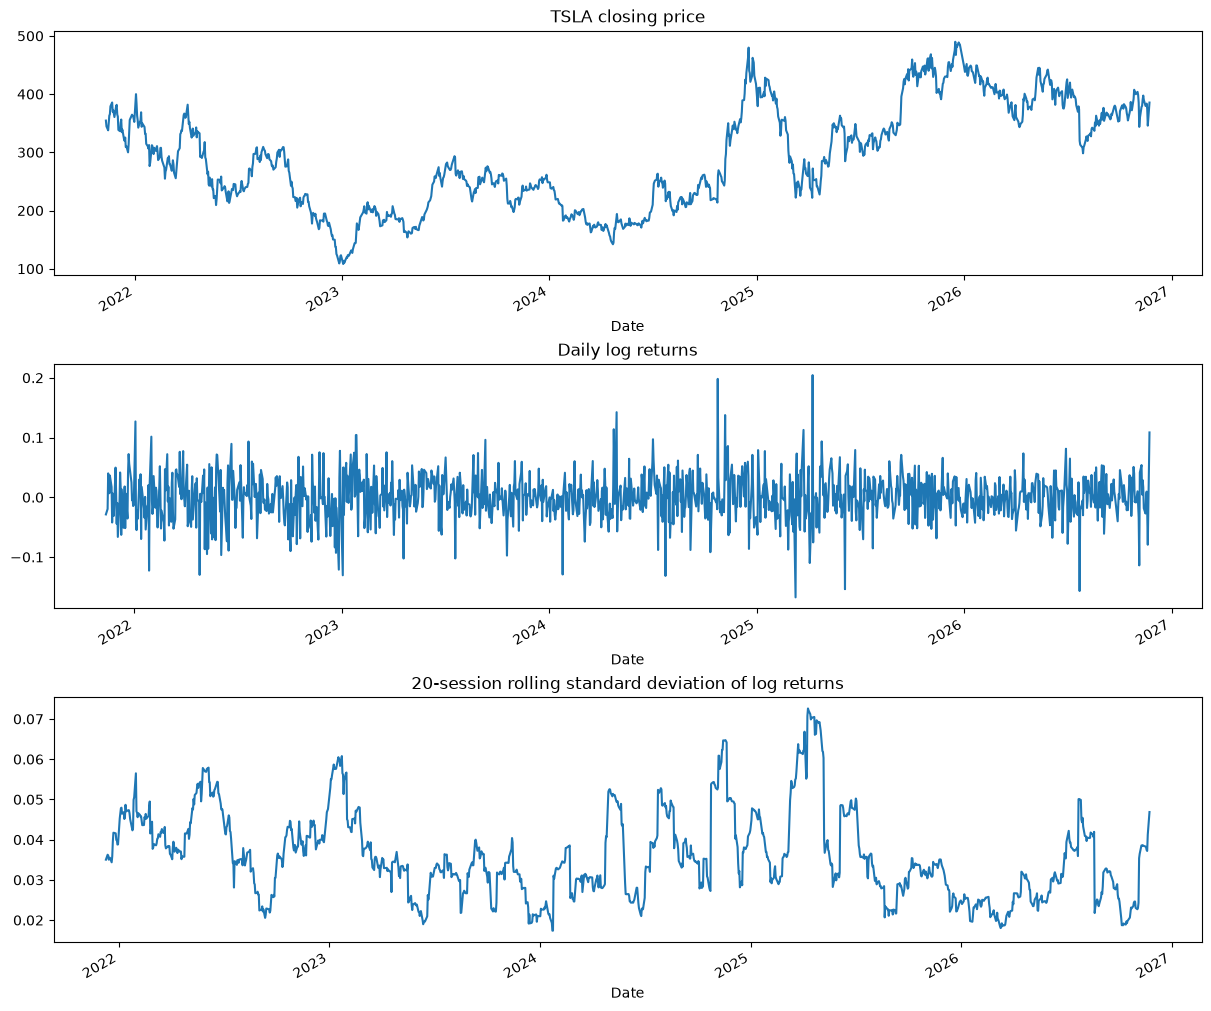

In [5]:
log_returns = np.log(prices).diff().dropna()
summary = pd.DataFrame({"close": prices.describe(), "log_return": log_returns.describe()})
display(summary)
fig, axes = plot_price_return_exploration(prices)
plt.show()

## 2. Exploratory plot

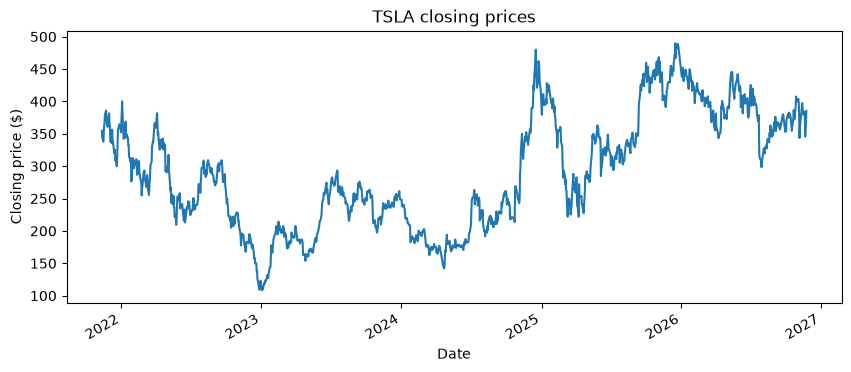

In [6]:
ax = prices.plot(figsize=(10, 4), title="TSLA closing prices")
ax.set_ylabel("Closing price ($)")
plt.show()

## Training-only stationarity and dependence diagnostics

Only the frozen initial training partition is used here. Do not use test-period evidence to select ARIMA orders or MLP hyperparameters.


/Users/jss/Desktop/code/python/environments/timeseriesproj/shared_code/evaluation/diagnostics.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(x,regression=regression,autolag=autolag)
/Users/jss/Desktop/code/python/environments/timeseriesproj/.venv/lib/python3.15/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.

,n,mean,std,skew,excess_kurtosis,adf_stat,adf_p,adf_lags,kpss_p,lb10_p,arch10_p
series,,,,,,,,,,,
training price,752,235.32644,56.77886,0.44342,-0.16094,-2.90056,0.04528,10.0,0.01,0.00000,0.00000
training price difference,751,-0.07669,9.22423,0.11057,2.97994,-7.94650,0.00000,9.0,0.10,0.00482,0.00000
training log returns,751,-0.00024,0.03841,0.05897,1.95853,-7.68554,0.00000,9.0,0.10,0.03426,0.00002


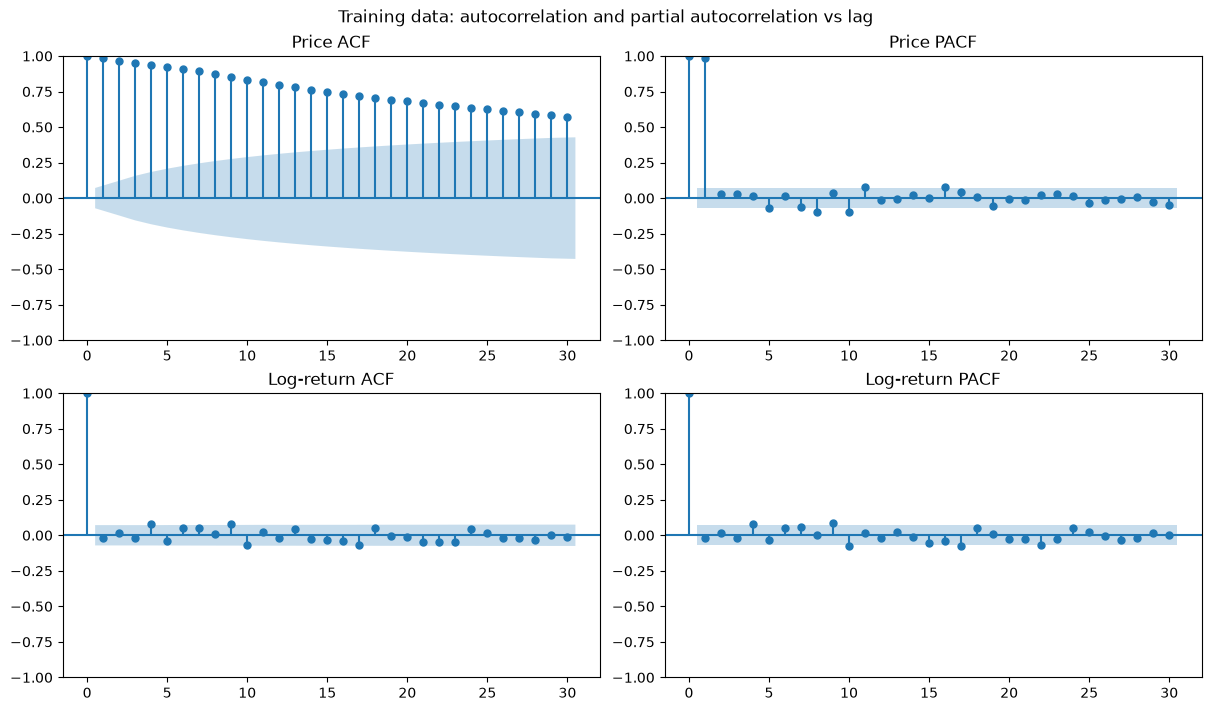

In [7]:
train_prices = fixed_train
train_log_returns = np.log(train_prices).diff().dropna()
diagnostic_table = training_diagnostic_table(train_prices)
display(diagnostic_table.round(5))
fig, axes = plot_training_acf_pacf(train_prices)
plt.show()

### Model configuration

These are starting parameters, not validated optimal settings. Tune using the training and validation periods before finalizing the frozen test evaluation.

In [8]:
print('Model:', MODEL_CLASS.__name__)
print('Parameters:', MODEL_KWARGS)

Model: RandomWalkDrift
Parameters: {}


## 3. Run the frozen historical backtest

The backtest uses the concatenated fixed CSVs as one ordered history. Validation and test **forecast targets** are fixed, while each rolling-origin fit may use observations preceding its target date.


In [9]:
results = run_forecasting_pipeline(
    prices=historical_prices,
    model_class=MODEL_CLASS,
    model_kwargs=MODEL_KWARGS,
    horizon=HORIZON,
    window_size=WINDOW_SIZE,
    train_end=train_end,
    validation_end=validation_end,
    interval_level=INTERVAL_LEVEL,
)
print("Model:", results.model_name)
print("Train:", results.train.index[0].date(), "to", results.train.index[-1].date())
print("Validation:", results.validation["target_date"].iloc[0], "to", results.validation["target_date"].iloc[-1])
print("Test:", results.test["target_date"].iloc[0], "to", results.test["target_date"].iloc[-1])
assert results.validation["target_date"].tolist() == list(fixed_validation.index)
assert results.test["target_date"].tolist() == list(fixed_test.index)


Model: RandomWalkDrift
Train: 2021-11-11 to 2024-11-07
Validation: 2024-11-08 00:00:00 to 2025-11-10 00:00:00
Test: 2025-11-11 00:00:00 to 2026-11-19 00:00:00


/Users/jss/Desktop/code/python/environments/timeseriesproj/.venv/lib/python3.15/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


## Rolling-origin backtests: validation and test
Detailed origin/target rows, and separate actual-vs-forecast and forecast-error panels.

VALIDATION BACKTEST


,origin_date,target_date,train_start,train_size,y_true,y_pred,error
0,2024-11-07,2024-11-08,2023-11-08,252,321.220001,297.208012,24.011990
1,2024-11-08,2024-11-11,2023-11-09,252,350.000000,321.663188,28.336812
2,2024-11-11,2024-11-12,2023-11-10,252,328.489990,350.539243,-22.049253
3,2024-11-12,2024-11-13,2023-11-13,252,330.239990,328.907440,1.332550
4,2024-11-13,2024-11-14,2023-11-14,252,311.179993,330.609831,-19.429838
5,2024-11-14,2024-11-15,2023-11-15,252,320.720001,311.452264,9.267738
6,2024-11-15,2024-11-18,2023-11-16,252,338.739990,321.067133,17.672858
7,2024-11-18,2024-11-19,2023-11-17,252,346.000000,339.156086,6.843914


TEST BACKTEST


,origin_date,target_date,train_start,train_size,y_true,y_pred,error
0,2025-11-10,2025-11-11,2024-11-07,252,439.619995,445.820927,-6.200932
1,2025-11-11,2025-11-12,2024-11-08,252,430.600006,440.091708,-9.491702
2,2025-11-12,2025-11-13,2024-11-11,252,401.989990,430.921122,-28.931131
3,2025-11-13,2025-11-14,2024-11-12,252,404.350006,402.282819,2.067187
4,2025-11-14,2025-11-17,2024-11-13,252,408.920013,404.645265,4.274748
5,2025-11-17,2025-11-18,2024-11-14,252,401.250000,409.309416,-8.059416
6,2025-11-18,2025-11-19,2024-11-15,252,403.989990,401.570837,2.419154
7,2025-11-19,2025-11-20,2024-11-18,252,395.230011,404.249950,-9.019939


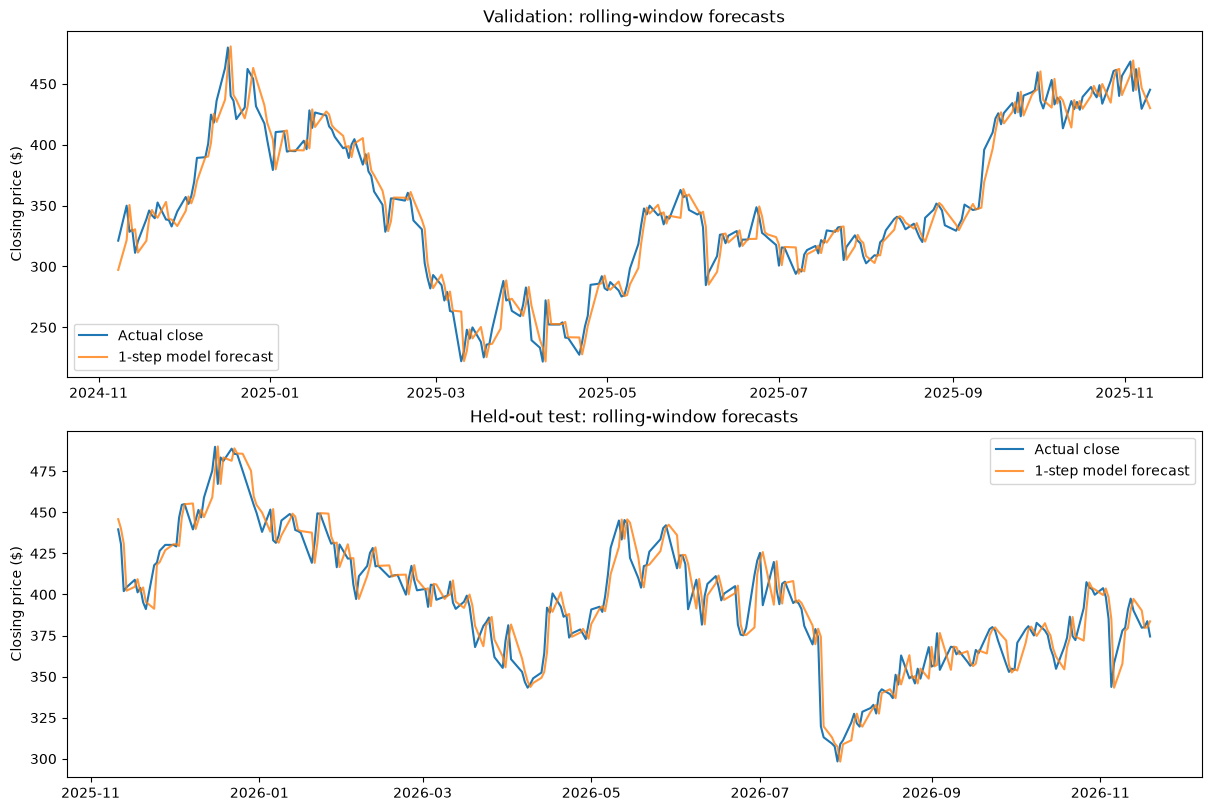

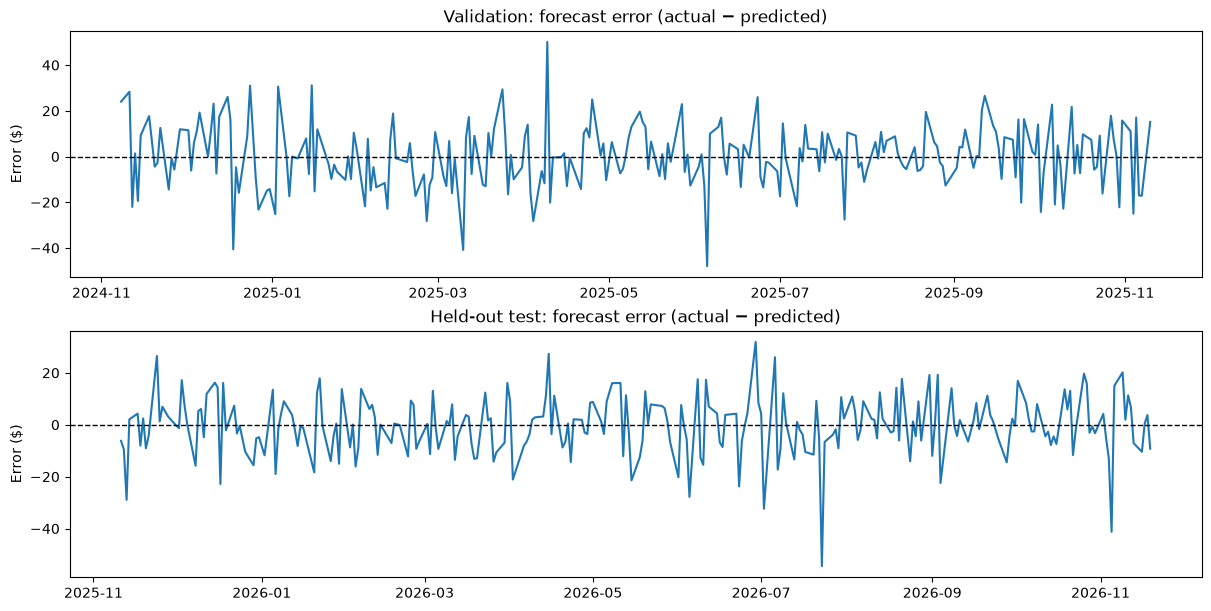

In [10]:
columns = ["origin_date", "target_date", "train_start", "train_size", "y_true", "y_pred", "error"]
print("VALIDATION BACKTEST")
display(results.validation[columns].head(8))
print("TEST BACKTEST")
display(results.test[columns].head(8))
for bt in (results.validation, results.test):
    assert (bt["horizon"] == 1).all()
    assert (bt["train_size"] == min(WINDOW_SIZE, len(results.train))).all()
    assert (bt["origin_date"] < bt["target_date"]).all()
assert set(results.validation["target_date"]).isdisjoint(set(results.test["target_date"]))
fig, axes = plot_backtest_comparison(results.validation, results.test)
plt.show()
fig, axes = plot_backtest_errors(results.validation, results.test)
plt.show()

## 4. Validation diagnostics and calibration errors

,n_errors,mean_error,std_error,t_pvalue,HAC_pvalue,LB_5_pvalue,LB_10_pvalue,ARCH_pvalue
0,251,0.041419,13.780145,0.962058,0.957996,0.450776,0.789007,0.985368


,origin_date,target_date,horizon,model,strategy,train_start,train_size,y_true,y_pred,error,split
0,2024-11-07,2024-11-08,1,RandomWalkDrift,rolling,2023-11-08,252,321.220001,297.208012,24.011990,validation
1,2024-11-08,2024-11-11,1,RandomWalkDrift,rolling,2023-11-09,252,350.000000,321.663188,28.336812,validation
2,2024-11-11,2024-11-12,1,RandomWalkDrift,rolling,2023-11-10,252,328.489990,350.539243,-22.049253,validation
3,2024-11-12,2024-11-13,1,RandomWalkDrift,rolling,2023-11-13,252,330.239990,328.907440,1.332550,validation
4,2024-11-13,2024-11-14,1,RandomWalkDrift,rolling,2023-11-14,252,311.179993,330.609831,-19.429838,validation


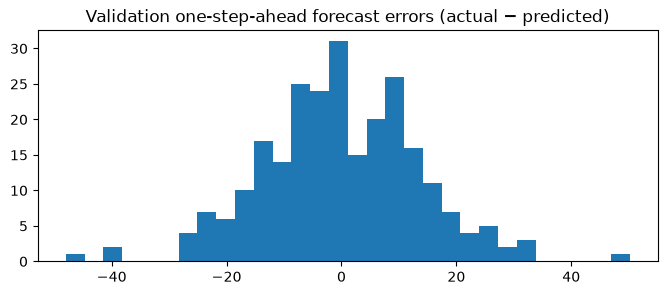

In [11]:
display(results.validation_diagnostics)
display(results.validation.head())
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(results.validation["error"], bins=30)
ax.set_title("Validation one-step-ahead forecast errors (actual − predicted)")
plt.show()

### Validation forecast-error diagnostics and dependence plots

,lb_stat,lb_pvalue
5,4.721724,0.450776
10,6.305159,0.789007


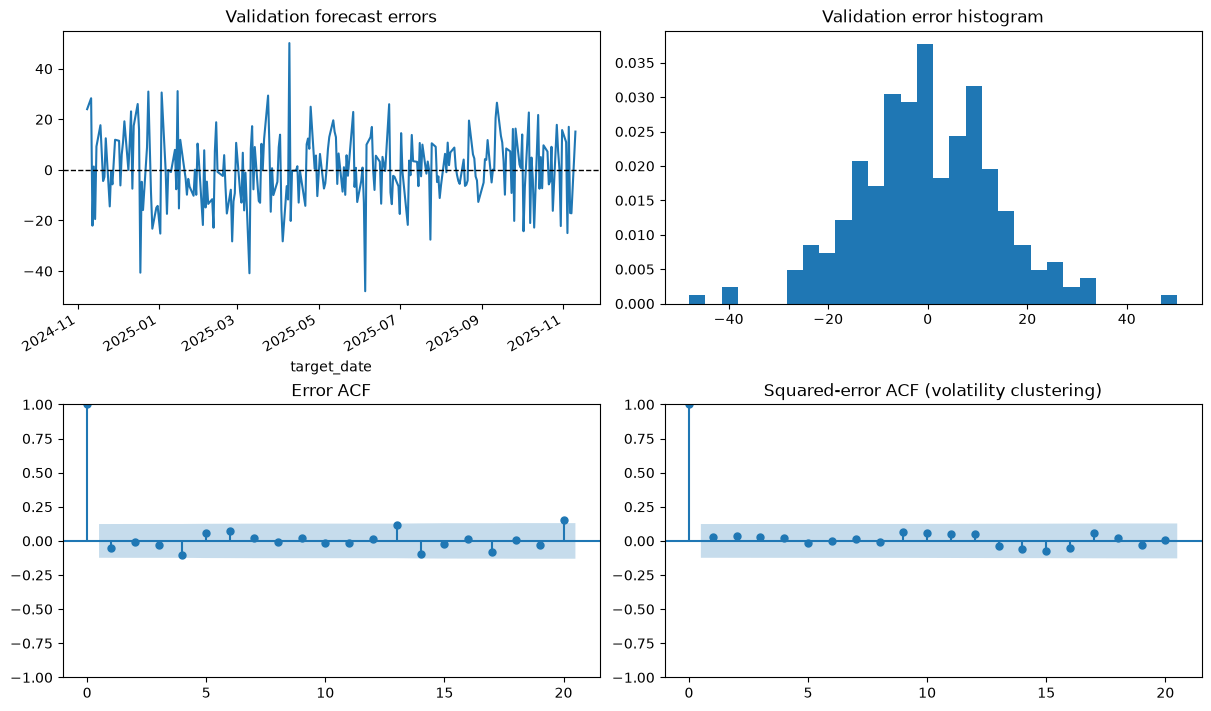

In [12]:
errors = results.validation.set_index("target_date")["error"].astype(float)
lb_lags = [lag for lag in (5, 10) if lag < len(errors)]
display(ljung_box_test(errors, lags=lb_lags))
fig, axes = plot_validation_error_diagnostics(results.validation)
plt.show()

## 5. Held-out test evaluation

,period,n_forecasts,MSE,RMSE,MAE,RMSLE,mean_error,predictive_mean_MSE,predictive_mean_RMSE,predictive_mean_MAE,predictive_mean_RMSLE,interval_coverage,mean_interval_width
0,validation,251,189.137557,13.752729,10.717990,0.041664,0.041419,NaN,NaN,NaN,NaN,NaN,NaN
1,test,258,127.039993,11.271202,8.482128,0.028896,-0.455108,127.079409,11.27295,8.482951,0.028898,0.972868,51.740919


,nominal_coverage,empirical_test_coverage,mean_interval_width_dollars,n_test_forecasts
0,0.95,0.9729,51.7409,258


,forecast,test_MSE,test_RMSE,test_MAE,test_RMSLE
0,Model point forecast,127.0400,11.2712,8.4821,0.0289
1,Validation-bias-adjusted predictive mean,127.0794,11.2730,8.4830,0.0289


,origin_date,target_date,y_true,y_pred,predictive_mean,interval_lower,interval_upper,covered
0,2025-11-10,2025-11-11,439.619995,445.820927,445.862346,420.641727,472.382645,True
1,2025-11-11,2025-11-12,430.600006,440.091708,440.133127,414.912508,466.653426,True
2,2025-11-12,2025-11-13,401.989990,430.921122,430.962541,405.741921,457.482840,False
3,2025-11-13,2025-11-14,404.350006,402.282819,402.324238,377.103618,428.844537,True
4,2025-11-14,2025-11-17,408.920013,404.645265,404.686684,379.466064,431.206983,True
5,2025-11-17,2025-11-18,401.250000,409.309416,409.350835,384.130215,435.871134,True
6,2025-11-18,2025-11-19,403.989990,401.570837,401.612256,376.391636,428.132555,True
7,2025-11-19,2025-11-20,395.230011,404.249950,404.291369,379.070750,430.811668,True
8,2025-11-20,2025-11-21,391.089996,395.426146,395.467566,370.246946,421.987865,True
9,2025-11-21,2025-11-24,417.779999,391.285454,391.326874,366.106254,417.847173,True


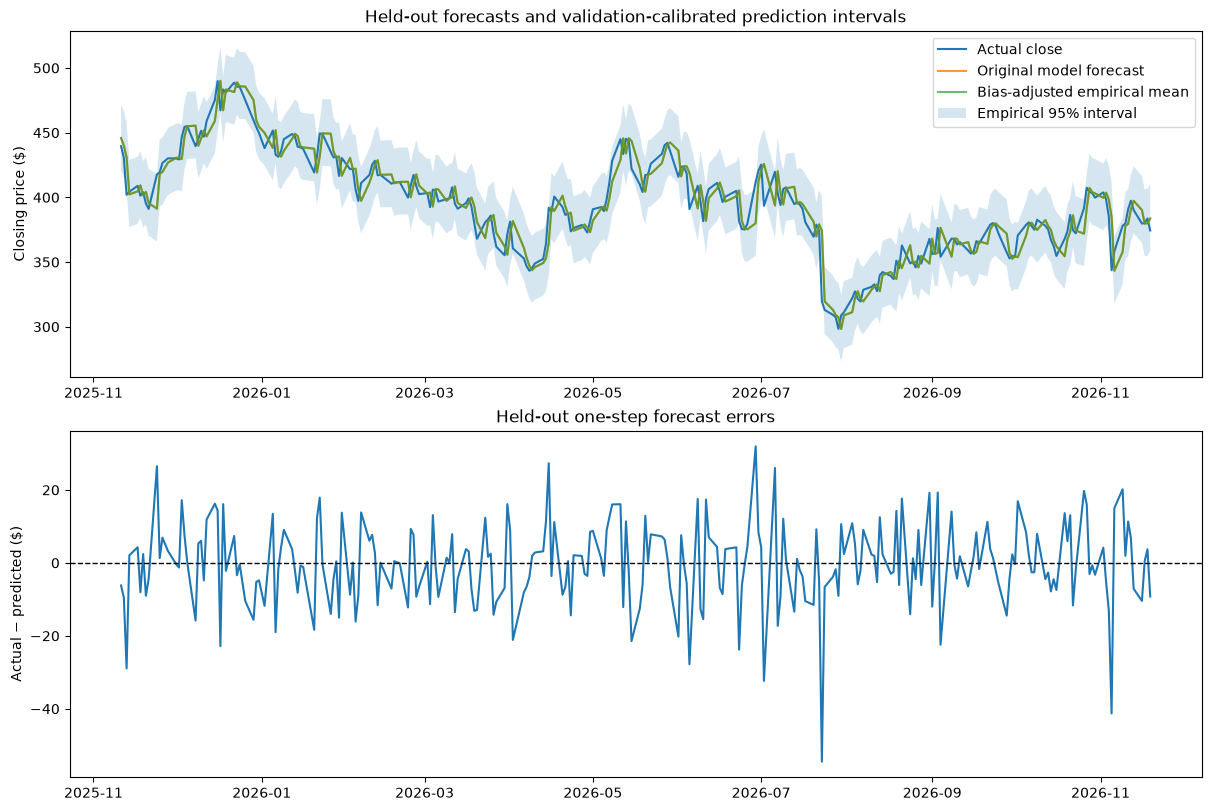

In [13]:
display(results.evaluation)
check = results.test.copy()
coverage_summary = interval_summary(check, level=INTERVAL_LEVEL)
point_comparison = compare_point_forecasts(check)
display(coverage_summary.round(4))
display(point_comparison.round(4))
display(check[["origin_date", "target_date", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper", "covered"]].head(10))
fig, axes = plot_test_intervals_and_errors(check, level=INTERVAL_LEVEL)
plt.show()

## 6. Latest next-session forecast (separate from frozen historical evaluation)

Fit the selected model specification on the latest completed 252 trading-day closes. Reuse the **frozen validation errors** to construct the empirical predictive distribution. The frozen test CSVs and their metrics are not updated.


Live forecast data verified through: 2026-11-23
Eligible prospective forecast: 2026-11-23 -> 2026-11-24


,origin_date,target_date,model,y_true,y_pred,predictive_mean,interval_lower,interval_upper,interval_level,last_close
0,2026-11-23,2026-11-24,RandomWalkDrift,NaN,385.437561,385.47898,360.25836,411.999279,0.95,385.459991


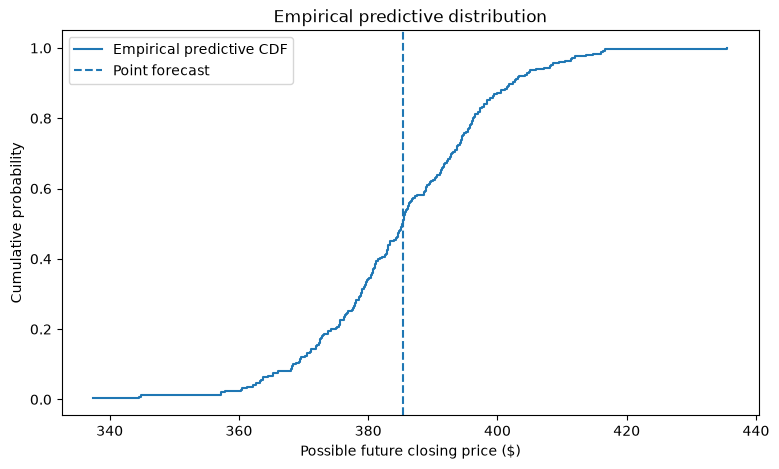

In [14]:
# verification
# Verify that the data is current before live forecasting.
from stock_pred.src.data.import_data import (
    latest_completed_nyse_session
)

latest_completed = latest_completed_nyse_session()
latest_observed = pd.Timestamp(prices.index[-1]).normalize()

assert latest_observed == latest_completed, (
    f"Stale dataset: latest observed={latest_observed.date()}, "
    f"latest completed NYSE session={latest_completed.date()}"
)

print(
    "Live forecast data verified through:",
    latest_observed.date()
)


# Refit the fixed model specification on the latest available prices.
live_model = MODEL_CLASS(**MODEL_KWARGS)
live_model.fit(prices.iloc[-WINDOW_SIZE:].to_numpy(dtype=float))
live_point = float(np.asarray(live_model.predict(HORIZON), dtype=float)[-1])
live_distribution = EmpiricalPredictiveDistribution(live_point, results.calibration_errors)
live_lower, live_upper = live_distribution.interval(INTERVAL_LEVEL)

# Determine whether this can be recorded as a genuinely prospective forecast.
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas_market_calendars as mcal

nyse = mcal.get_calendar("NYSE")
now = pd.Timestamp(datetime.now(ZoneInfo("America/New_York")))
origin = pd.Timestamp(prices.index[-1]).normalize()

# NYSE schedules include holidays and early closing days.
schedule = nyse.schedule(
    start_date=min(origin, now.tz_localize(None).normalize()) - pd.Timedelta(days=20),
    end_date=max(origin, now.tz_localize(None).normalize()) + pd.Timedelta(days=20),
)
completed = schedule.loc[schedule["market_close"] <= now.tz_convert("UTC")]
if completed.empty:
    raise RuntimeError("No completed NYSE session found in calendar window")
latest_completed_session = pd.Timestamp(completed.index[-1]).normalize()

future_sessions = schedule.index[schedule.index > origin]
if len(future_sessions) == 0:
    raise RuntimeError("Could not identify the next NYSE session")
target_date = pd.Timestamp(future_sessions[0]).normalize()
target_close = schedule.loc[target_date, "market_close"]

is_prospective = bool(
    origin >= TEST_END_DATE
    and target_date > TEST_END_DATE
    and origin == latest_completed_session
    and now.tz_convert("UTC") < target_close
)

if not is_prospective:
    print("NOT ELIGIBLE FOR LIVE HISTORY: forecast is stale or target is already closed.")
    print(f"Latest CSV close: {origin.date()} | Latest completed NYSE session: {latest_completed_session.date()}")
    print(f"Target: {target_date.date()} | Current NY time: {now}")
else:
    print(f"Eligible prospective forecast: {origin.date()} -> {target_date.date()}")

live_forecast = pd.DataFrame([{
    "origin_date": origin,
    "target_date": target_date,
    "model": MODEL_CLASS.__name__,
    "y_true": np.nan,
    "y_pred": live_point,
    "predictive_mean": live_distribution.mean(),
    "interval_lower": live_lower,
    "interval_upper": live_upper,
    "interval_level": INTERVAL_LEVEL,
    "last_close": float(prices.iloc[-1]),
}])
display(live_forecast)
ax = plot_predictive_cdf(live_distribution)
plt.show()

### Empirical predictive sample distribution

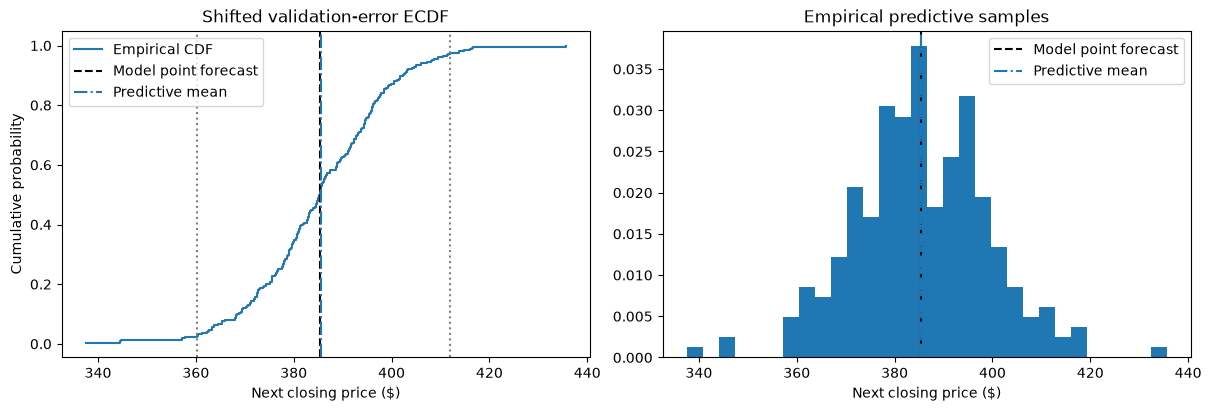

In [15]:
fig, axes = plot_predictive_distribution(live_distribution, level=INTERVAL_LEVEL)
plt.show()


## 7. Export standardized results for `main.ipynb`

The frozen historical test results are always exported. A prospective forecast is appended **only if** the origin is the latest completed NYSE session and the target session has not closed. An existing forecast is never overwritten. Do not backfill old forecasts as if they were issued live.

In [16]:
EXPORT_COLUMNS = [
    "origin_date",
    "target_date",
    "model",
    "y_true",
    "y_pred",
    "predictive_mean",
    "interval_lower",
    "interval_upper",
]

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------
# 1. Preserve the frozen historical benchmark
# ---------------------------------------------

test_path = RESULTS_DIR / "random_walk_drift_test.csv"

if not test_path.exists():
    results.test[EXPORT_COLUMNS].to_csv(
        test_path, index=False
    )
    print("Created frozen historical test results.")
else:
    print("Historical test results already frozen; not overwritten.")


# ---------------------------------------------
# 2. Load prospective forecast history
# ---------------------------------------------

history_path = RESULTS_DIR / "random_walk_drift_live_history.csv"

if history_path.exists():
    history = pd.read_csv(history_path)
else:
    history = pd.DataFrame(columns=EXPORT_COLUMNS)

# Normalize dates to ensure correct matching
for col in ["origin_date", "target_date"]:
    history[col] = pd.to_datetime(history[col]).dt.normalize()

actual_prices = prices.copy()
actual_prices.index = pd.to_datetime(actual_prices.index).normalize()

# ---------------------------------------------
# 3. Reconcile actual observed closing prices
# ---------------------------------------------

observed_actuals = history["target_date"].map(actual_prices)

history["y_true"] = pd.to_numeric(
    history["y_true"], errors="coerce"
).combine_first(observed_actuals)

# ---------------------------------------------
# 4. Append new eligible prospective forecast
# ---------------------------------------------

if is_prospective:

    new_forecast = live_forecast[EXPORT_COLUMNS].copy()

    key_cols = ["model", "origin_date", "target_date"]

    duplicate = (
        (history["model"] == MODEL_CLASS.__name__)
        & (history["origin_date"] == origin)
        & (history["target_date"] == target_date)
    ).any()

    if duplicate:
        print("Forecast already recorded; preserving original.")
    else:
        history = pd.concat(
            [history, new_forecast],
            ignore_index=True
        )
        print("New prospective forecast appended.")

else:
    print("No new eligible prospective forecast.")

# ---------------------------------------------
# 5. Save updated prospective history
# ---------------------------------------------

history = history.sort_values(
    ["origin_date", "target_date"]
).reset_index(drop=True)

history.to_csv(history_path, index=False)

print("Saved:", history_path)
display(history.tail())

Historical test results already frozen; not overwritten.
New prospective forecast appended.
Saved: /Users/jss/Desktop/code/python/environments/timeseriesproj/stock_pred/results/random_walk_drift_live_history.csv


,origin_date,target_date,model,y_true,y_pred,predictive_mean,interval_lower,interval_upper
0,2026-11-20,2026-11-23,RandomWalkDrift,385.459991,345.623155,345.664574,320.443954,372.184873
1,2026-11-23,2026-11-24,RandomWalkDrift,NaN,385.437561,385.478980,360.258360,411.999279
